In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

data=pd.read_csv('Real estate.csv')

In [33]:
data.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [35]:
data.size

3312

In [37]:
data.describe()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


In [39]:
data.dtypes

No                                          int64
X1 transaction date                       float64
X2 house age                              float64
X3 distance to the nearest MRT station    float64
X4 number of convenience stores             int64
X5 latitude                               float64
X6 longitude                              float64
Y house price of unit area                float64
dtype: object

In [47]:
data=data.drop(columns=['No','X1 transaction date'])

In [59]:
data.head()

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1


In [61]:
data.isna().sum()

X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [63]:
data.duplicated().sum()

0

In [194]:
X = data.drop('Y house price of unit area', axis=1)


In [196]:
y=data['Y house price of unit area']

In [198]:
#x=x.values.reshape(-1,1)

In [200]:
#scaling

In [202]:
from sklearn.preprocessing import StandardScaler


In [204]:
sd=StandardScaler()

In [206]:
x_sca=sd.fit_transform(x)   #normalise the diffrerence

In [208]:
x_sca

array([[ 1.25562833, -0.79249504,  2.00740743,  1.12542986,  0.44876222],
       [ 0.15708622, -0.61661163,  1.66750286,  0.91244418,  0.40113894],
       [-0.38779067, -0.41401527,  0.30788458,  1.48686011,  0.68818339],
       ...,
       [ 0.09556786, -0.54967846,  0.98769372,  0.82289338,  0.42397202],
       [-0.84478419, -0.77668389,  0.30788458, -0.18475479,  0.4768143 ],
       [-0.98539758, -0.78807071,  1.66750286,  0.42757905,  0.63534112]])

In [210]:
from sklearn.model_selection import train_test_split

In [211]:
x_train,x_test,y_train,y_test=train_test_split(x_sca,y,test_size=0.25)


In [212]:
from sklearn.linear_model import LinearRegression

In [213]:
reg=LinearRegression()

In [218]:
reg.fit(x_train,y_train)   #trining the data using train data

LinearRegression()

In [220]:
reg.coef_

array([-3.2136618 , -4.97643178,  3.86284915,  2.90001447, -0.07363462])

In [222]:
reg.intercept_

38.42935600892683

In [224]:
y_pred=reg.predict(x_test)

In [226]:
y_pred

array([24.07699846, 46.42446778, 34.5756329 , 30.38166456, 50.39964253,
       38.77132185, 46.15227666, 42.09529672, 38.19599568, 48.14793126,
       44.52836708, 47.58392629, 40.36023525, 49.02619908, 33.62886895,
       46.76854599, 32.56655531, 40.31585234, 46.43501154, 42.18880224,
       45.74835193, 41.12306368, 30.22237329, 46.45754039, 46.35955325,
       34.02462688, 30.59951912, 40.69636823, 45.51476019,  8.93940217,
       33.04453559, 31.21984815, 24.26111311, 43.5417795 , 43.40749118,
       40.77889064, 42.52469311, 24.31651232, 44.55660982, 38.20298361,
       33.61532924, 40.57345873, 43.34935205, 53.32184146, 43.11274221,
       44.09452437, 53.18062775, 27.95935494, 33.64175293, 45.32930591,
       37.48581646, 41.17545628, 52.64517701, 50.05093534, 42.74750293,
       32.18823304, 40.71467244, 46.34490485, 48.32522851, 42.28205628,
       54.11475451, 36.09909391, 33.62922848, 52.43880517, 35.1313896 ,
       46.74169862, 15.00493943, 41.47907782, 32.85210526, 53.15

Text(0, 0.5, 'Y house price of unit area')

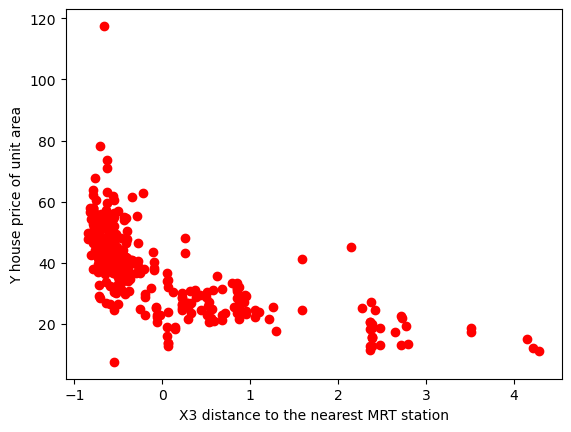

In [250]:
plt.scatter(x_train[:, 1], y_train, color='red')  # index 1 = 2nd column
plt.xlabel("X3 distance to the nearest MRT station")
plt.ylabel("Y house price of unit area")

